# 04 · Numbers and Arithmetic

> **Why the math wobbles.** Humans read numbers in groups of three from the
> right (place value). A tokenizer splits digits however they co-occurred in
> text, cutting across those groups — so the model never receives numbers in a
> place-value-respecting form.

In [1]:
import os
import sys
import pathlib

_p = pathlib.Path.cwd()
while not (_p / "pyproject.toml").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p)
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))

import json

import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

from src.artifacts import save_figure, save_json

print("repo root:", _p)

repo root: /workspaces/tokenization_101


## How digits split

In [2]:
from src.bpe import BPETokenizer
from src.datasets.corpora import number_strings, training_corpus
from src.probes.numbers import place_value_groups, probe_numbers

tok = BPETokenizer().train(training_corpus(60_000), vocab_size=512)

rows = []
for n in number_strings():
    pr = probe_numbers(tok, n)
    rows.append(
        {
            "text": n,
            "pieces": pr.pieces,
            "digit_pieces": pr.digit_pieces,
            "place_value": pr.place_value,
            "respects_place_value": pr.respects_place_value,
        }
    )
    print(f"{n!r:>30}  digits -> {pr.digit_pieces}   place-value -> {pr.place_value}")

print("saved:", save_json("04_numbers", rows))

                     '1234567'  digits -> ['1', '2', '3', '4', '5', '6', '7']   place-value -> ['1', '234', '567']
                     '1000000'  digits -> ['1', '0', '0', '0', '0', '0', '0']   place-value -> ['1', '000', '000']
                    '42424242'  digits -> ['4', '2', '4', '2', '4', '2', '4', '2']   place-value -> ['42', '424', '242']
                     '3.14159'  digits -> ['3', '1', '4', '1', '5', '9']   place-value -> ['314', '159']
                 '1234 + 5678'  digits -> ['1', '2', '3', '4', '5', '6', '7', '8']   place-value -> ['12', '345', '678']
 'The year 2024 had 366 days.'  digits -> ['2', '0', '2', '4', '3', '6', '6']   place-value -> ['2', '024', '366']
saved: /workspaces/tokenization_101/outputs/data/04_numbers.json


Notice the digit split almost never lines up with the place-value grouping a human would use.

saved: /workspaces/tokenization_101/outputs/figures/04_number_breakdown.png


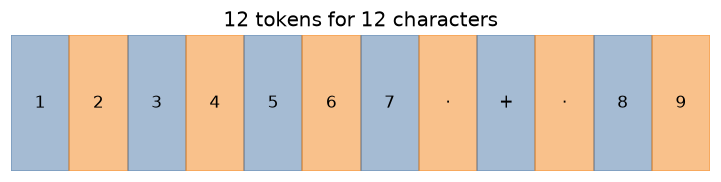

In [3]:
from src.visualisation import plot_token_breakdown

fig = plot_token_breakdown(tok, "1234567 + 89")
print("saved:", save_figure(fig, "04_number_breakdown"))
plt.show()

saved: /workspaces/tokenization_101/outputs/figures/04_tokens_per_number.png


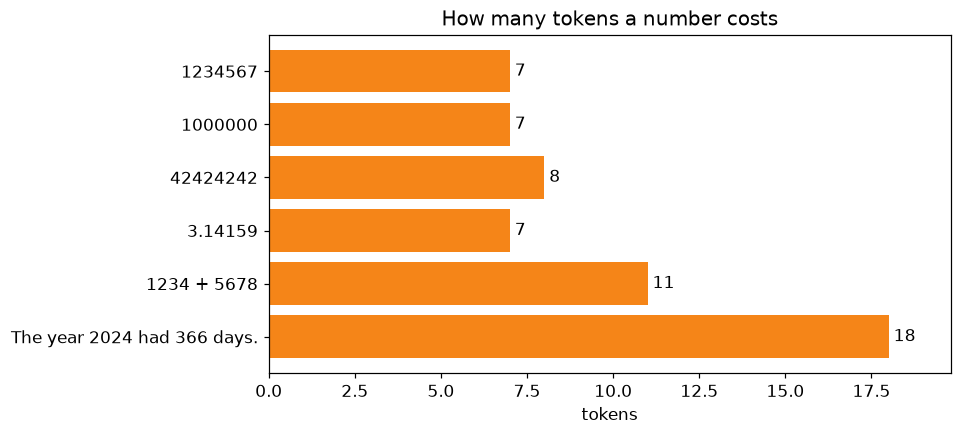

In [4]:
labels = [r["text"] for r in rows]
counts = [len(r["pieces"]) for r in rows]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(labels, counts, color="#F58518")
ax.invert_yaxis()
ax.set_xlabel("tokens")
ax.set_title("How many tokens a number costs")
ax.set_xlim(0, max(counts) * 1.10)  # headroom so the value labels are not clipped
for y, c in enumerate(counts):
    ax.text(c, y, f" {c}", va="center")
print("saved:", save_figure(fig, "04_tokens_per_number"))
plt.show()

**Takeaway.** Because digits are grouped inconsistently and against place value,
multi-digit arithmetic is unreliable for a concrete, mechanical reason. Route it
to a calculator or use digit-level handling.